# Wadi Ghadir gravity – 3-D density inversion with SimPEG

**Wadi Ghadir, Eastern Desert, Egypt · complete Bouguer anomaly (ρ = 2.67 g/cm³)**

**Written by Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook inverts the complete Bouguer anomalies of the Wadi Ghadir gravity stations for a 3-D density-contrast
model with [SimPEG](https://simpeg.xyz). It is the first of three:

| Notebook | Data | Unknown |
|---|---|---|
| **06 (this one)** | gravity stations, complete Bouguer anomaly | density contrast Δρ [g/cm³] |
| 07 | magnetic readings, total-field anomaly | magnetic susceptibility χ [SI] |
| 08 | both | Δρ and χ together, coupled by a cross-gradient term |

All three use **the same mesh, topography and data preparation** (functions in `wghadir/inversion.py`), so their models
can be compared cell by cell.

**The steps**

| Step | Content |
|---:|---|
| 1 | Load the station anomalies (table 16 of the gravity chain) |
| 2 | Separate the regional field of deep sources from the residual |
| 3 | Thin the stations (block median) and assign uncertainties |
| 4 | Topography and the 3-D tensor mesh; active cells below the ground |
| 5 | Survey, forward simulation and sensitivity |
| 6 | The inversion: data misfit, regularisation, bounds, directives; run |
| 7 | Data fit: observed, predicted and normalised residuals |
| 8 | The density model: depth slices and cross-sections |
| 9 | Export (NumPy, UBC-GIF mesh and model, CSV, summary) |

**Read the results with care.** A gravity anomaly can be explained by infinitely many density models. The inversion
returns the *simplest* (smallest and smoothest, sensitivity-weighted) model that fits the data to their errors. It
shows where mass excess or deficit is likely; depths and shapes depend on the regularisation.

Each step has **✏️ PARAMETERS** (edit and re-run from there), **▶ PROCESSING** and **📊 RESULT** cells. The
complete notebook runs in about a minute.

## 0  Set-up

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}
import contextlib
import io
import json
import logging
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

import discretize
import simpeg
from simpeg import data, data_misfit, directives, inverse_problem, inversion, maps, optimization, regularization
from simpeg.potential_fields import gravity, magnetics

from wghadir import inversion as W

OUT_DIR = os.path.join(REPO, "outputs", "inversion")
os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("SimPEG", simpeg.__version__, "| discretize", discretize.__version__, "| outputs in", os.path.abspath(OUT_DIR))

SimPEG 0.25.2 | discretize 0.12.0 | outputs in /home/user/MooSobh/outputs/inversion


## 1  The station anomalies

The gravity chain (`notebooks/01_Gravity_Processing.ipynb`, table `outputs/tables/16_field_stations_relative.csv`)
provides for every field station the complete Bouguer anomaly relative to base 100, its uncertainty (propagated
reading, drift and height errors) and the GNSS position and orthometric height (EGM2008). Terrain effects of the
Copernicus GLO-30 DEM are already removed with 2.67 g/cm³; the inversion therefore solves for density *contrasts*
relative to 2.67 g/cm³, and cells of the topography belong to the model.

In [2]:
# ✏️ PARAMETERS – edit and re-run from here
RHO_REDUCTION = 2.67      # Bouguer density of the reduction (g/cm³): one of 2.00, 2.20, ..., 3.00
SENSOR_HEIGHT_M = 0.25    # CG-6 sensor above the station mark

In [3]:
# ▶ PROCESSING
grav = W.load_gravity(REPO, rho=RHO_REDUCTION, sensor_m=SENSOR_HEIGHT_M)
print(f"{len(grav)} stations; complete Bouguer anomaly {grav.cb.min():.2f} … {grav.cb.max():.2f} mGal; "
      f"median uncertainty {grav.sigma.median() * 1000:.0f} µGal; elevations {grav.z.min():.0f}–{grav.z.max():.0f} m")
grav.describe().loc[["mean", "std", "min", "max"], ["cb", "sigma", "z"]].round(3)

984 stations; complete Bouguer anomaly -13.95 … 9.42 mGal; median uncertainty 61 µGal; elevations 2–490 m


,cb,sigma,z
mean,1.387,0.049,272.465
std,4.900,0.019,106.311
min,-13.953,0.031,2.482
max,9.418,0.088,489.780


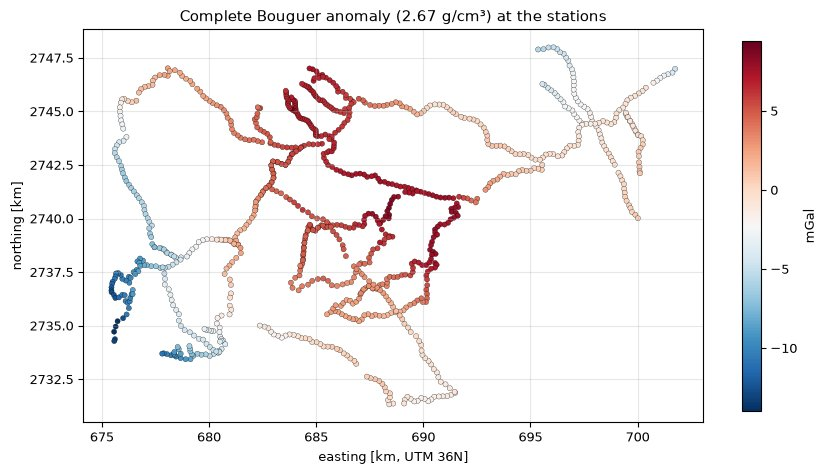

In [4]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(grav.e / 1000, grav.n / 1000, c=grav.cb, s=14, cmap="RdBu_r", edgecolor="k", linewidth=0.2)
ax.set(aspect="equal", xlabel="easting [km, UTM 36N]", ylabel="northing [km]", title=f"Complete Bouguer anomaly ({RHO_REDUCTION} g/cm³) at the stations")
plt.colorbar(sc, ax=ax, label="mGal", shrink=0.8)
plt.show()

## 2  Regional and residual

The complete Bouguer anomaly rises by about 20 mGal from south-west to north-east: the effect of deep crustal
structure, far below the depth the stations can resolve. Inverting it would push mass to the edges and bottom of the
mesh. It is therefore removed first:

* `"upward"` (default): the regional field of notebook 03, the gridded anomaly upward-continued by 3 km
  (`outputs/open_source/Wadi_Ghadir_OpenSource_Grids.nc`), sampled at the stations;
* `"polynomial"`: a least-squares polynomial surface of degree `TREND_DEGREE`;
* `"none"`: invert the complete Bouguer anomaly as it is.

In [5]:
# ✏️ PARAMETERS – edit and re-run from here
REGIONAL = "upward"       # "upward", "polynomial" or "none"
TREND_DEGREE = 1

In [6]:
# ▶ PROCESSING
if REGIONAL == "upward":
    grav["regional"] = W.regional_from_grid(REPO, grav.e.values, grav.n.values)
elif REGIONAL == "polynomial":
    grav["regional"] = W.polynomial_trend(grav.e.values, grav.n.values, grav.cb.values, TREND_DEGREE)
else:
    grav["regional"] = 0.0
grav["residual"] = grav.cb - grav.regional
print(f"regional {grav.regional.min():.2f} … {grav.regional.max():.2f} mGal; residual {grav.residual.min():.2f} … {grav.residual.max():.2f} mGal "
      f"(std {grav.residual.std():.2f} mGal)")

regional -6.16 … 2.89 mGal; residual -8.07 … 6.98 mGal (std 2.70 mGal)


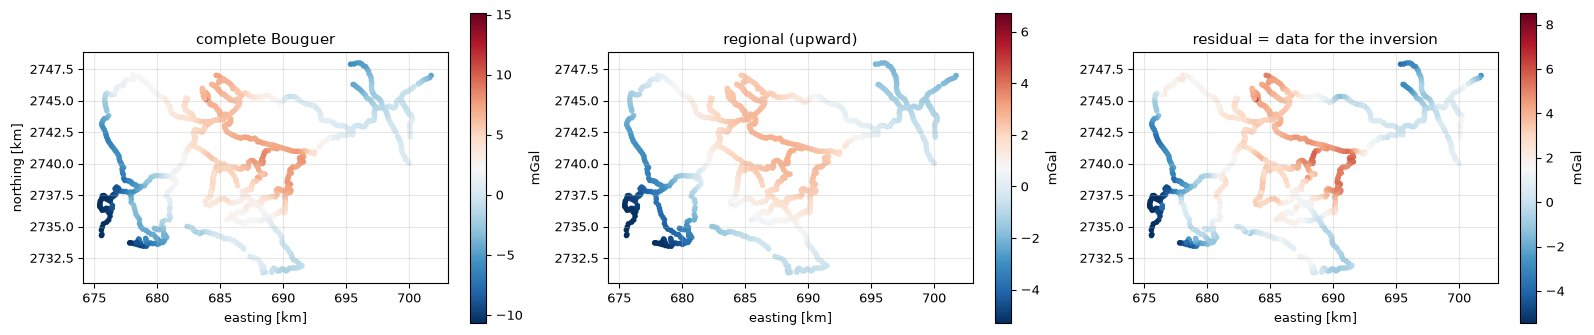

In [7]:
# 📊 RESULT
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, col, title in ((axes[0], "cb", "complete Bouguer"), (axes[1], "regional", f"regional ({REGIONAL})"), (axes[2], "residual", "residual = data for the inversion")):
    v = grav[col]
    lim = np.nanpercentile(np.abs(v - v.median()), 98)
    sc = ax.scatter(grav.e / 1000, grav.n / 1000, c=v, s=9, cmap="RdBu_r", vmin=v.median() - lim, vmax=v.median() + lim)
    ax.set(aspect="equal", title=title, xlabel="easting [km]")
    plt.colorbar(sc, ax=ax, label="mGal", shrink=0.75)
axes[0].set_ylabel("northing [km]")
plt.tight_layout()
plt.show()

## 3  Thinning and uncertainties

Stations along the wadis are often only 100–200 m apart, much closer than the cells of the mesh. One median per
block of `BLOCK_M` metres keeps the information and removes redundancy (and the occasional outlier). Each block value
gets an uncertainty: a floor (`FLOOR_MGAL`, larger than the measurement error because it also absorbs the
regional–residual separation and the discretisation) plus a fraction of the value.

The residual has no absolute level (relative gravity, regional removed), so its median is subtracted.
SimPEG's `gz` points **up**, so the downward-positive anomaly enters with a minus sign.

In [8]:
# ✏️ PARAMETERS – edit and re-run from here
BLOCK_M = 400.0           # block-median size (≈ the horizontal cell size)
FLOOR_MGAL = 0.05         # uncertainty floor
PERCENT = 0.02            # plus this fraction of |data|

In [9]:
# ▶ PROCESSING
gb = W.block_median(grav, ["residual", "sigma"], BLOCK_M)
gb["data"] = gb.residual - gb.residual.median()
gb["uncertainty"] = FLOOR_MGAL + PERCENT * np.abs(gb.data)
d_obs = -gb.data.values                            # SimPEG convention: gz positive upward
unc = gb.uncertainty.values
print(f"{len(grav)} stations -> {len(gb)} blocks ({gb.n_block.max()} stations in the fullest block); "
      f"data {gb.data.min():.2f} … {gb.data.max():.2f} mGal; uncertainty {unc.min():.3f}–{unc.max():.3f} mGal")

984 stations -> 481 blocks (8 stations in the fullest block); data -9.43 … 4.25 mGal; uncertainty 0.050–0.239 mGal


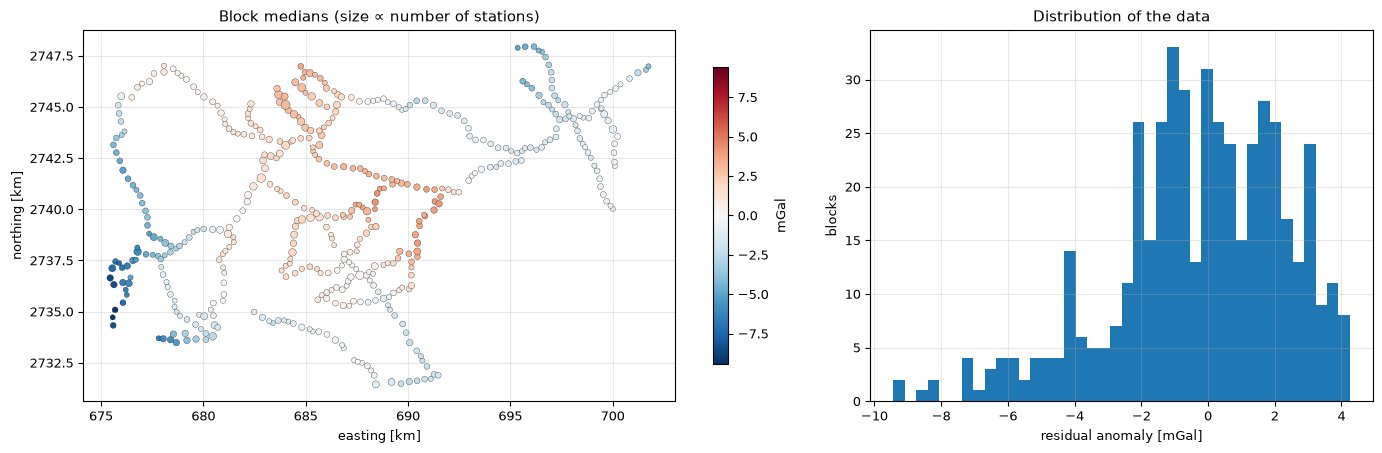

In [10]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
sc = axes[0].scatter(gb.e / 1000, gb.n / 1000, c=gb.data, s=10 + 4 * gb.n_block, cmap="RdBu_r", edgecolor="k", linewidth=0.2,
                     vmin=-np.abs(gb.data).max(), vmax=np.abs(gb.data).max())
axes[0].set(aspect="equal", xlabel="easting [km]", ylabel="northing [km]", title="Block medians (size ∝ number of stations)")
plt.colorbar(sc, ax=axes[0], label="mGal", shrink=0.8)
axes[1].hist(gb.data, bins=40, color="C0")
axes[1].set(xlabel="residual anomaly [mGal]", ylabel="blocks", title="Distribution of the data")
plt.tight_layout()
plt.show()

## 4  Topography and mesh

A tensor mesh covers all gravity *and* magnetic data plus a margin (the same mesh is used in notebooks 07 and 08):
400 m × 400 m × 100 m core cells, expanding padding cells to the sides and below. The top of the mesh is the highest
point of the Copernicus GLO-30 topography; cells above the ground are **inactive** (air) and are not part of the model.

In [11]:
# ✏️ PARAMETERS – edit and re-run from here
CORE_DX_M = 400.0          # horizontal core cell size
CORE_DZ_M = 100.0          # vertical core cell size
N_CORE_Z = 20              # core layers (100 m each) below the top of the mesh
N_PAD_XY, N_PAD_Z = 5, 8   # padding cells, expanding by 1.3
REGION_PAD_M = 1000.0      # margin around all gravity and magnetic data (same mesh in notebooks 06, 07 and 08)

In [12]:
# ▶ PROCESSING
grav_all = W.load_gravity(REPO)
mag_all, FIELD = W.load_magnetics(REPO)
region = W.survey_region(grav_all, mag_all, pad_m=REGION_PAD_M)        # same for both data sets
topo = W.topography(REPO, region)
inside = (topo[:, 0] >= region[0]) & (topo[:, 0] <= region[1]) & (topo[:, 1] >= region[2]) & (topo[:, 1] <= region[3])
z_top = np.ceil(topo[inside, 2].max() / CORE_DZ_M) * CORE_DZ_M
mesh = W.build_mesh(region, dx=CORE_DX_M, dz=CORE_DZ_M, n_core_z=N_CORE_Z, n_pad_xy=N_PAD_XY, n_pad_z=N_PAD_Z, z_top=z_top)
active = W.active_cells(mesh, topo)
n_active = int(active.sum())
print(f"region {(region[1] - region[0]) / 1000:.1f} × {(region[3] - region[2]) / 1000:.1f} km; topography {topo[inside, 2].min():.0f}–{topo[inside, 2].max():.0f} m")
print(f"mesh {mesh.shape_cells} = {mesh.n_cells:,} cells, {n_active:,} active (below the topography); "
      f"depth extent {mesh.h[2].sum() / 1000:.1f} km, top at {z_top:.0f} m")

region 28.3 × 18.7 km; topography 0–771 m
mesh (81, 57, 28) = 129,276 cells, 105,895 active (below the topography); depth extent 5.1 km, top at 800 m


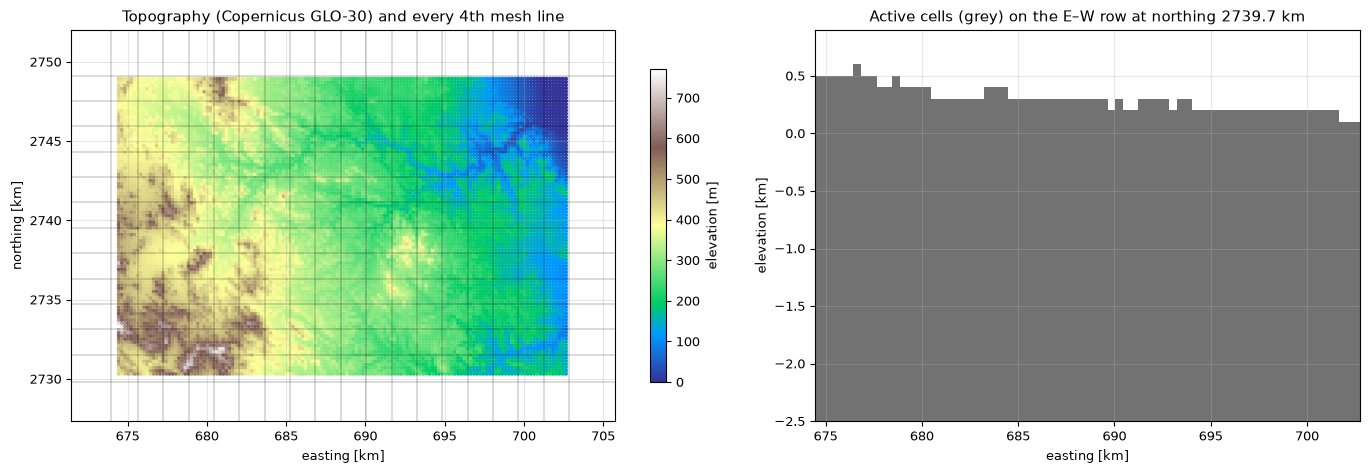

In [13]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ti = topo[inside]
sc = axes[0].scatter(ti[:, 0] / 1000, ti[:, 1] / 1000, c=ti[:, 2], s=4, cmap="terrain", vmin=0)
for xx in mesh.nodes_x[::4]:
    axes[0].axvline(xx / 1000, color="k", lw=0.2)
for yy in mesh.nodes_y[::4]:
    axes[0].axhline(yy / 1000, color="k", lw=0.2)
axes[0].set(xlim=(region[0] / 1000 - 3, region[1] / 1000 + 3), ylim=(region[2] / 1000 - 3, region[3] / 1000 + 3), aspect="equal",
            xlabel="easting [km]", ylabel="northing [km]", title="Topography (Copernicus GLO-30) and every 4th mesh line")
plt.colorbar(sc, ax=axes[0], label="elevation [m]", shrink=0.8)
j = mesh.shape_cells[1] // 2
act3 = active.reshape(mesh.shape_cells, order="F")[:, j, :].T
axes[1].pcolormesh(mesh.nodes_x / 1000, mesh.nodes_z / 1000, act3, cmap="Greys", shading="flat", vmin=0, vmax=1.6)
axes[1].set(xlim=(region[0] / 1000, region[1] / 1000), ylim=(-2.5, z_top / 1000 + 0.1), xlabel="easting [km]", ylabel="elevation [km]",
            title=f"Active cells (grey) on the E–W row at northing {mesh.cell_centers_y[j] / 1000:.1f} km")
plt.tight_layout()
plt.show()

## 5  Survey, simulation and sensitivity

Each block becomes a receiver at the sensor height above the station (`gz`, in mGal). The integral formulation
computes the gravity of every active cell at every receiver with Choclo's prism kernels and stores this sensitivity
matrix **G** (data × cells) in memory: *d = G m*.

The sensitivity of a cell decays with depth. Without compensation the inversion would put all the mass right below the
stations; SimPEG counteracts this with **sensitivity weighting** (Li & Oldenburg 1998; directive
`UpdateSensitivityWeights`), which scales the regularisation of each cell by its total sensitivity.

In [14]:
# ▶ PROCESSING
receivers = gravity.receivers.Point(gb[["e", "n", "z"]].values, components="gz")
survey = gravity.survey.Survey(gravity.sources.SourceField(receiver_list=[receivers]))
model_map = maps.IdentityMap(nP=n_active)
sim = gravity.simulation.Simulation3DIntegral(survey=survey, mesh=mesh, rhoMap=model_map, active_cells=active,
                                              engine="choclo", store_sensitivities="ram")
tic = time.time()
G = sim.G
sens = np.sqrt((G ** 2).sum(axis=0))                 # column norms: total sensitivity of every cell
print(f"G: {G.shape[0]} data × {G.shape[1]:,} cells ({G.nbytes / 1e6:.0f} MB) in {time.time() - tic:.1f} s")

G: 481 data × 105,895 cells (204 MB) in 3.3 s


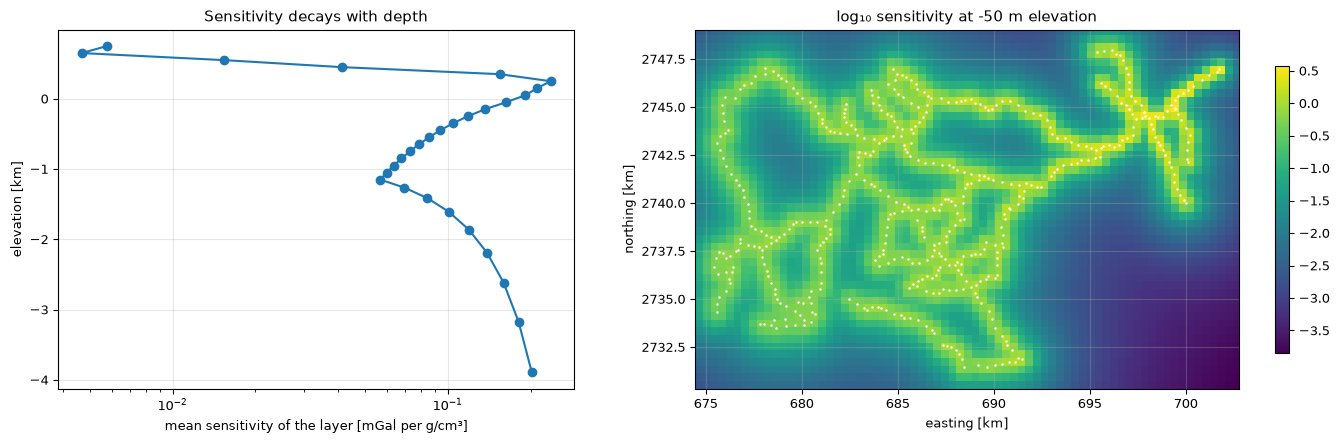

In [15]:
# 📊 RESULT
full = W.model_on_mesh(mesh, active, sens)
v = full.reshape(mesh.shape_cells, order="F")
layer_mean = np.nanmean(v, axis=(0, 1))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].semilogx(layer_mean, mesh.cell_centers_z / 1000, "o-")
axes[0].set(xlabel="mean sensitivity of the layer [mGal per g/cm³]", ylabel="elevation [km]", title="Sensitivity decays with depth")
x, y, s0, z0 = W.depth_slice(mesh, full, 0.0, 0.0)            # at sea level
m = axes[1].pcolormesh(x / 1000, y / 1000, np.log10(s0), cmap="viridis", shading="auto")
axes[1].plot(gb.e / 1000, gb.n / 1000, "w.", ms=1.5)
axes[1].set(aspect="equal", xlim=(region[0] / 1000, region[1] / 1000), ylim=(region[2] / 1000, region[3] / 1000),
            title=f"log₁₀ sensitivity at {z0:.0f} m elevation", xlabel="easting [km]", ylabel="northing [km]")
plt.colorbar(m, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()

## 6  The inversion

SimPEG minimises

$$\phi(m) = \phi_d(m) + \beta\,\phi_m(m), \qquad \phi_d = \left\| W_d (G m - d^{obs}) \right\|^2, \qquad
\phi_m = \alpha_s \|W_s m\|^2 + \alpha_x \|W_x \partial_x m\|^2 + \alpha_y \|W_y \partial_y m\|^2 + \alpha_z \|W_z \partial_z m\|^2$$

* **Data misfit** `L2DataMisfit`, weighted by 1/uncertainty; the target is φ_d ≈ number of data (χ² = 1).
* **Regularisation** `WeightedLeastSquares`: smallness (α_s) and smoothness in x, y, z, all sensitivity-weighted.
* **Optimisation** `ProjectedGNCG`: Gauss–Newton with conjugate gradients, keeping Δρ within `BOUNDS`.
* **Directives**: initial β from the largest eigenvalues (`BetaEstimate_ByEig`), β cooling (`BetaSchedule`),
  Jacobi preconditioner, stop at the target misfit (`TargetMisfit`), and a log of every iteration.

In [16]:
# ✏️ PARAMETERS – edit and re-run from here
ALPHA_S, ALPHA_X, ALPHA_Y, ALPHA_Z = 1.0, 1.0, 1.0, 1.0
BOUNDS = (-1.0, 1.0)      # density contrast limits [g/cm³]
BETA0_RATIO = 10.0
COOLING_FACTOR = 2.0       # β is divided by this after every iteration
CHI_FACTOR = 1.0          # target misfit = CHI_FACTOR × number of data
MAX_ITER = 20

In [17]:
# ▶ PROCESSING
dobj = data.Data(survey, dobs=d_obs, standard_deviation=unc)
dmis = data_misfit.L2DataMisfit(data=dobj, simulation=sim)
reg = regularization.WeightedLeastSquares(mesh, active_cells=active, mapping=model_map,
                                          alpha_s=ALPHA_S, alpha_x=ALPHA_X, alpha_y=ALPHA_Y, alpha_z=ALPHA_Z)
opt = optimization.ProjectedGNCG(maxIter=MAX_ITER, lower=BOUNDS[0], upper=BOUNDS[1], maxIterLS=20, cg_maxiter=30, cg_rtol=1e-3)
inv_prob = inverse_problem.BaseInvProblem(dmis, reg, opt)
log = W.iteration_log()
directive_list = [directives.UpdateSensitivityWeights(every_iteration=False),
                  directives.BetaEstimate_ByEig(beta0_ratio=BETA0_RATIO, random_seed=0),
                  directives.BetaSchedule(coolingFactor=COOLING_FACTOR, coolingRate=1),
                  directives.UpdatePreconditioner(),
                  directives.TargetMisfit(chifact=CHI_FACTOR), log]
tic = time.time()
with contextlib.redirect_stdout(io.StringIO()) as simpeg_log:
    rho = inversion.BaseInversion(inv_prob, directiveList=directive_list).run(np.zeros(n_active))
seconds = time.time() - tic
d_pred = sim.dpred(rho)
print(f"{len(log.rows)} iterations in {seconds:.0f} s; φ_d = {log.rows[-1]['phi_d']:.0f} (target {CHI_FACTOR * len(d_obs):.0f}); "
      f"Δρ {rho.min():.3f} … {rho.max():.3f} g/cm³")
log.table

9 iterations in 8 s; φ_d = 424 (target 481); Δρ -0.141 … 0.135 g/cm³


,iteration,beta,phi_d,phi_m
0,1,0.022778,113624.047184,9.064411e+05
1,2,0.011389,77681.293522,2.039070e+06
2,3,0.005695,47453.127524,3.924807e+06
3,4,0.002847,25927.842715,6.585956e+06
4,5,0.001424,12770.888785,9.811503e+06
5,6,0.000712,5774.777232,1.321646e+07
6,7,0.000356,2461.259978,1.642340e+07
7,8,0.000178,1020.039106,1.920248e+07
8,9,0.000089,424.329608,2.149609e+07


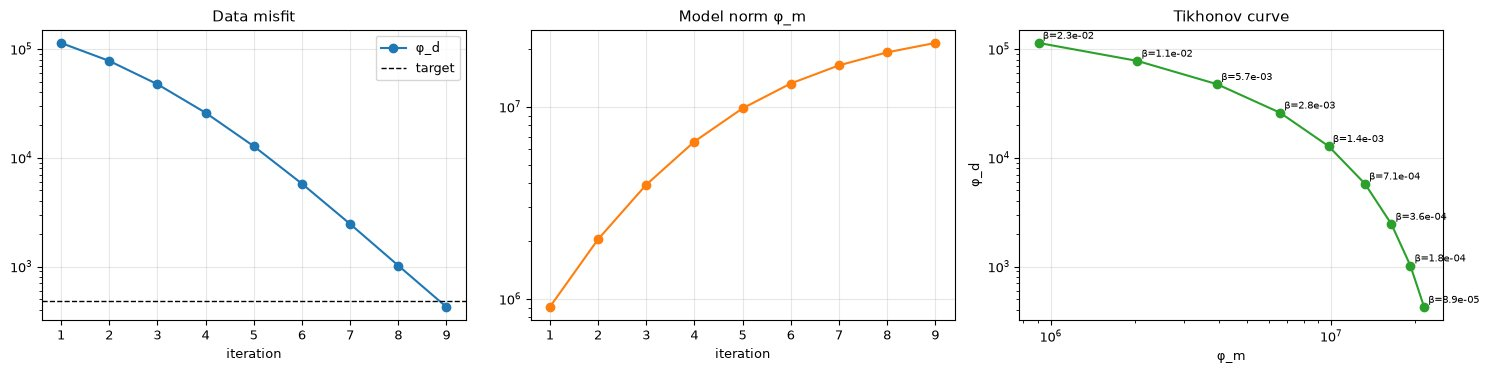

In [18]:
# 📊 RESULT
it = log.table
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].semilogy(it.iteration, it.phi_d, "o-", label="φ_d")
axes[0].axhline(CHI_FACTOR * len(d_obs), color="k", ls="--", lw=1, label="target")
axes[0].set(xlabel="iteration", title="Data misfit"); axes[0].legend()
axes[1].semilogy(it.iteration, it.phi_m, "o-", color="C1")
axes[1].set(xlabel="iteration", title="Model norm φ_m")
axes[2].loglog(it.phi_m, it.phi_d, "o-", color="C2")
for r in it.itertuples():
    axes[2].annotate(f"β={r.beta:.1e}", (r.phi_m, r.phi_d), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[2].set(xlabel="φ_m", ylabel="φ_d", title="Tikhonov curve")
plt.tight_layout()
plt.show()

## 7  Data fit

Observed and predicted anomaly, and the normalised residual (observed − predicted) / uncertainty. A good fit leaves
normalised residuals of about ±1 without spatial pattern.

In [19]:
# ▶ PROCESSING
obs, pred = -d_obs, -d_pred                         # back to the gravimeter convention (positive down)
nres = (obs - pred) / unc
print(f"rms misfit {np.sqrt(np.mean((obs - pred) ** 2)):.3f} mGal; χ² = {np.mean(nres ** 2):.2f}; "
      f"{np.mean(np.abs(nres) < 2) * 100:.0f} % of the normalised residuals within ±2")

rms misfit 0.107 mGal; χ² = 0.88; 95 % of the normalised residuals within ±2


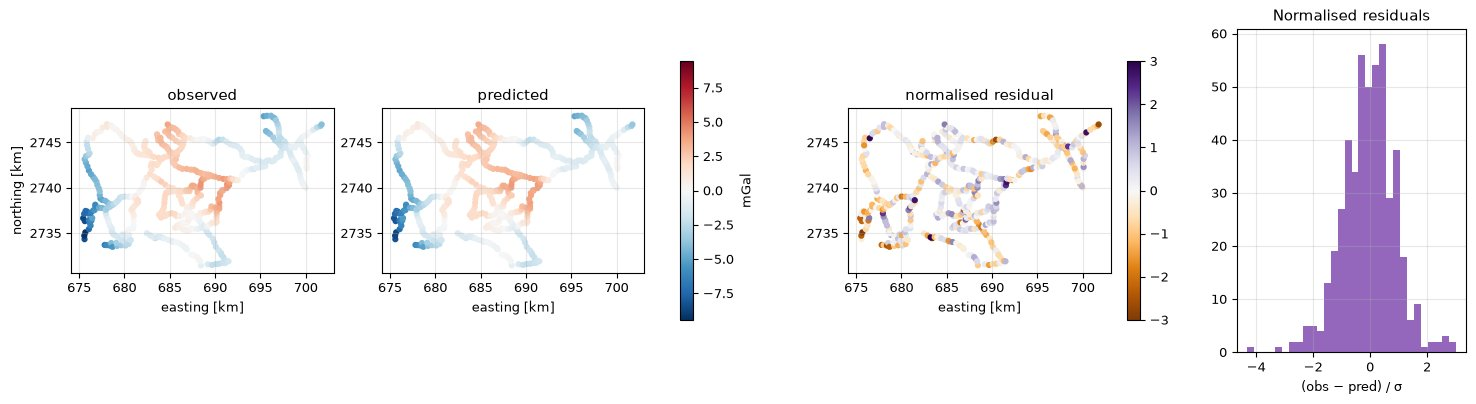

In [20]:
# 📊 RESULT
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 0.7]})
lim = np.abs(obs).max()
for ax, v, title in ((axes[0], obs, "observed"), (axes[1], pred, "predicted")):
    sc = ax.scatter(gb.e / 1000, gb.n / 1000, c=v, s=12, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set(aspect="equal", title=title, xlabel="easting [km]")
plt.colorbar(sc, ax=axes[:2], label="mGal", shrink=0.8)
sc = axes[2].scatter(gb.e / 1000, gb.n / 1000, c=nres, s=12, cmap="PuOr", vmin=-3, vmax=3)
axes[2].set(aspect="equal", title="normalised residual", xlabel="easting [km]")
plt.colorbar(sc, ax=axes[2], shrink=0.8)
axes[3].hist(nres, bins=30, color="C4")
axes[3].set(xlabel="(obs − pred) / σ", title="Normalised residuals")
axes[0].set_ylabel("northing [km]")
plt.show()

## 8  The density model

Horizontal slices at fixed elevations (the ground is at 0–770 m; blank where no data point lies within `MASK_M`, the model is unconstrained there) and vertical sections. The sections run east–west and
north–south through the survey and along the line A–B of notebook 04 (south-western low to the central high).

In [21]:
# ✏️ PARAMETERS – edit and re-run from here
SLICE_ELEVATIONS_M = (0.0, -600.0, -1500.0)   # elevation of the depth slices [m]
SECTIONS = {"A–B (notebook 04)": ((34.7448, 24.7058), (34.9490, 24.8117)),
            "W–E": ((34.70, 24.765), (35.00, 24.765)),
            "S–N": ((34.86, 24.68), (34.86, 24.85))}
SECTION_ZMIN_M = -2500.0
MASK_M = 2500.0           # slices: blank cells farther than this from any data point (unconstrained)

In [22]:
# ▶ PROCESSING
rho_full = W.model_on_mesh(mesh, active, rho)
lim = np.nanpercentile(np.abs(rho), 99)
print(f"density contrast: 1st–99th percentile {np.percentile(rho, 1):.3f} … {np.percentile(rho, 99):.3f} g/cm³")

density contrast: 1st–99th percentile -0.095 … 0.061 g/cm³


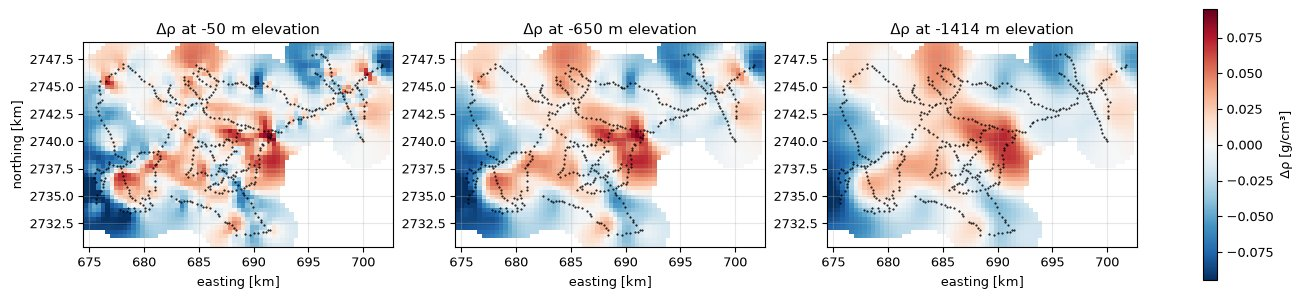

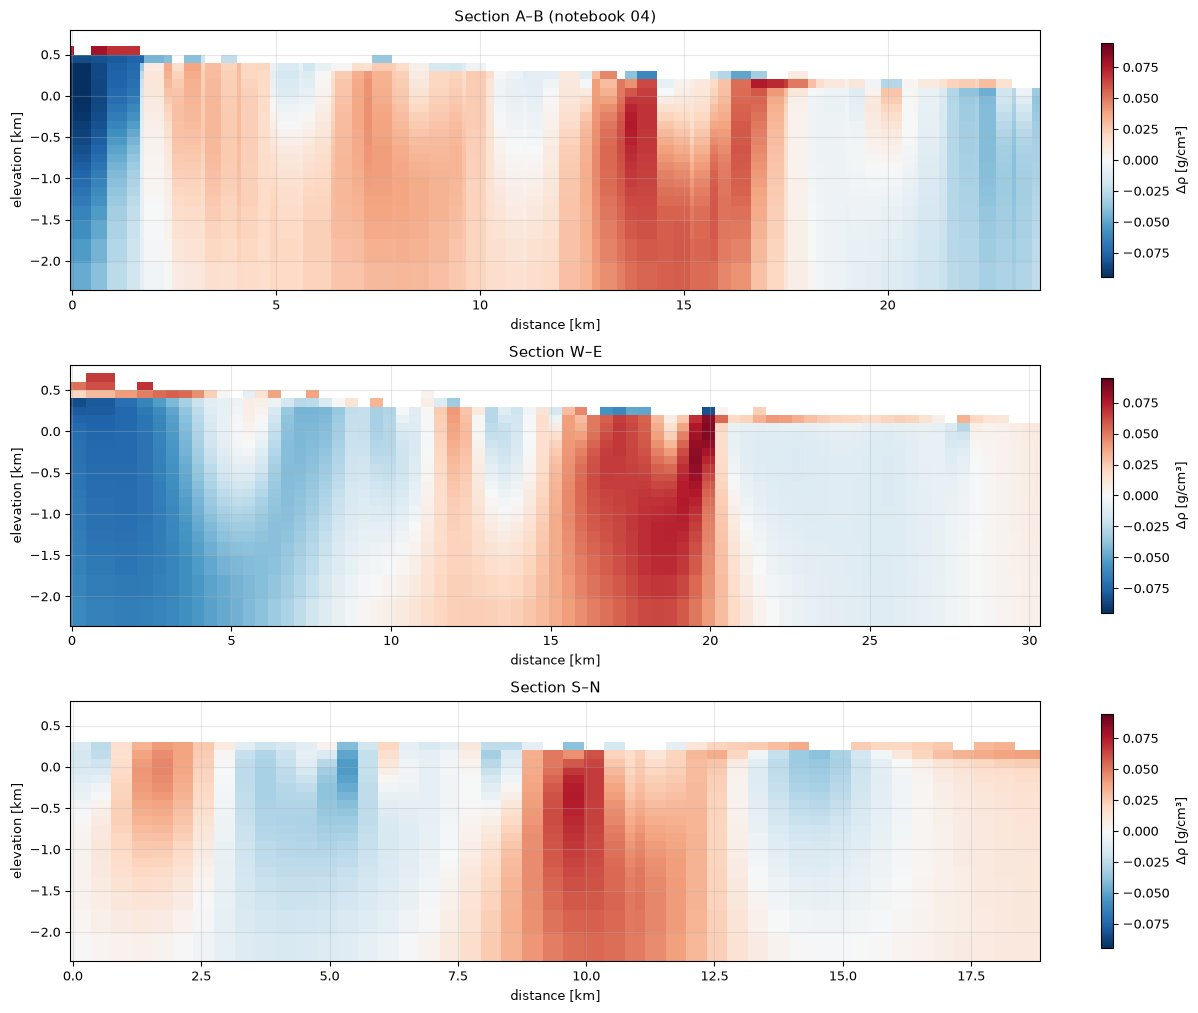

In [23]:
# 📊 RESULT
fig, axes = plt.subplots(1, len(SLICE_ELEVATIONS_M), figsize=(17, 4.4))
for ax, elev in zip(axes, SLICE_ELEVATIONS_M):
    x, y, s2, zz = W.depth_slice(mesh, rho_full, -elev, 0.0)
    s2 = np.where(W.far_from_data(x, y, gb.e, gb.n, MASK_M), np.nan, s2)
    m = ax.pcolormesh(x / 1000, y / 1000, s2, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.plot(gb.e / 1000, gb.n / 1000, "k.", ms=1)
    ax.set(aspect="equal", xlim=(region[0] / 1000, region[1] / 1000), ylim=(region[2] / 1000, region[3] / 1000),
           title=f"Δρ at {zz:.0f} m elevation", xlabel="easting [km]")
axes[0].set_ylabel("northing [km]")
plt.colorbar(m, ax=axes, label="Δρ [g/cm³]", shrink=0.8)
plt.show()

fig, axes = plt.subplots(len(SECTIONS), 1, figsize=(13, 3.4 * len(SECTIONS)))
for ax, (name, (a, b)) in zip(axes, SECTIONS.items()):
    (ea, na), (eb, nb_) = W.to_utm(*a), W.to_utm(*b)
    d, zc, sec = W.section(mesh, rho_full, (ea, na), (eb, nb_), zmin=SECTION_ZMIN_M)
    m = ax.pcolormesh(d / 1000, zc / 1000, sec, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.set(title=f"Section {name}", ylabel="elevation [km]", xlabel="distance [km]")
    plt.colorbar(m, ax=ax, label="Δρ [g/cm³]", shrink=0.9)
plt.tight_layout()
plt.show()

## 9  Export

`outputs/inversion/`: the model with its mesh as NumPy archive (read by notebook 08), the mesh and model in UBC-GIF
format (for 3-D viewers such as ParaView or Geoscience ANALYST), the data with predictions and residuals as CSV, the
iteration log and a summary.

In [24]:
# ▶ PROCESSING
np.savez_compressed(os.path.join(OUT_DIR, "gravity_model.npz"), rho_gcc=rho, active=active, hx=mesh.h[0], hy=mesh.h[1],
                    hz=mesh.h[2], origin=mesh.origin, data_xyz=gb[["e", "n", "z"]].values, data_mgal=obs, predicted_mgal=pred,
                    uncertainty_mgal=unc)
files = W.save_ubc(mesh, {"density_gcc": rho_full}, os.path.join(OUT_DIR, "ubc"), "wadi_ghadir_gravity")
out = gb[["e", "n", "z", "n_block"]].assign(observed_mGal=obs, predicted_mGal=pred, uncertainty_mGal=unc, normalised_residual=nres)
lon, lat = W.to_lonlat(out.e.values, out.n.values)
out.insert(0, "lat", lat); out.insert(0, "lon", lon)
with open(os.path.join(OUT_DIR, "gravity_data_fit.csv"), "w") as fh:
    fh.write("# Wadi Ghadir SimPEG gravity inversion (notebook 06), written by Mohamed Sobh, LIAG. Residual complete Bouguer anomaly, block medians.\n")
    out.to_csv(fh, index=False, float_format="%.5f")
log.table.to_csv(os.path.join(OUT_DIR, "gravity_iterations.csv"), index=False)
summary = {"written_by": W.AUTHOR, "data": int(len(gb)), "stations": int(len(grav)), "regional": REGIONAL, "block_m": BLOCK_M,
           "uncertainty": {"floor_mgal": FLOOR_MGAL, "percent": PERCENT}, "mesh": list(mesh.shape_cells), "active_cells": n_active,
           "iterations": len(log.rows), "seconds": round(seconds, 1), "chi2": float(np.mean(nres ** 2)),
           "rms_mgal": float(np.sqrt(np.mean((obs - pred) ** 2))), "rho_range_gcc": [float(rho.min()), float(rho.max())],
           "alphas": [ALPHA_S, ALPHA_X, ALPHA_Y, ALPHA_Z], "bounds": list(BOUNDS)}
json.dump(summary, open(os.path.join(OUT_DIR, "gravity_summary.json"), "w"), indent=1)
print("written:", sorted(f for f in os.listdir(OUT_DIR) if f.startswith("gravity")), files)

written: ['gravity_data_fit.csv', 'gravity_iterations.csv', 'gravity_model.npz', 'gravity_summary.json'] ['wadi_ghadir_gravity_density_gcc.mod', 'wadi_ghadir_gravity_mesh.msh']


---
### References

* Cockett, R., Kang, S., Heagy, L. J., Pidlisecky, A. & Oldenburg, D. W. (2015). SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications. *Computers & Geosciences* 85.
* Li, Y. & Oldenburg, D. W. (1998). 3-D inversion of gravity data. *Geophysics* 63.
* Uieda, L. et al. (2023). Choclo: kernel functions for potential fields. Fatiando a Terra.

*Written by Mohamed Sobh, LIAG.*